# Layer 3 in practice: active galactic nuclei

This notebook executes the material of {doc}`../layer3_agn`: the chain from halo
mass to X-ray luminosity at the default parameters, the luminosity function it
predicts against two published fits, the occupation of haloes by AGNs above a
luminosity threshold, the obscured fraction, and the black holes themselves.
It runs on a `pip install` of `ggah_mod` plus `matplotlib`.
Layer 3 is work in progress, and the notice it emits on import is silenced below.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

import warnings

import matplotlib.pyplot as plt
import numpy as np

import ggah_mod
warnings.filterwarnings("ignore", category=ggah_mod.WorkInProgressWarning)

import ggah_mod.sectors as S
from ggah_mod import DIFFERENTIABLE
from ggah_mod.cosmology import PLANCK18, make_pk
from ggah_mod.halos.field import make_field
from ggah_mod.sectors import agn as A

plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (6.4, 4.0),
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"ggah_mod {ggah_mod.__version__}, jax {jax.__version__}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod 1.7.0, jax 0.10.2


## The halo field and the galaxies

The AGN sector reads the stellar masses of a galaxy sector whose occupation is
a stellar-mass threshold, here the default `zumandelbaum15` at its defaults.
The field is at $z = 0.2$, as on the galaxy page.
The calibration check is switched off: Powell et al.'s relation was fitted at
$z \le 0.1$, and the sector would warn at every redshift above it.

In [2]:
Z = 0.2
field = make_field(PLANCK18, DIFFERENTIABLE, make_pk("emu_pk"), z=Z)
m = np.asarray(field.m)
lgm = np.log10(m)
ok = (m > 3e10) & (m < 3e15)

gal = S.GalaxySector("zumandelbaum15", calibration="off")
gp = S.galaxy_defaults("zumandelbaum15")
agn = S.AgnSector(gal, calibration="off")
split = S.AgnSector(gal, calibration="off", obscuration="split")
p, o = S.AgnParams(), S.ObscurationParams()
h = float(PLANCK18.h)

## The chain

*(a)* The mean central stellar mass and black-hole mass against halo mass.
*(b)* The duty cycle $f_{\rm ERDF}(M_\star)$, the fraction of black holes that
are active, capped smoothly at one.
*(c)* The Eddington-ratio distribution $\xi(\lambda)$ at three stellar masses,
times the duty cycle: the break moves with stellar mass through $\beta_\lambda$.

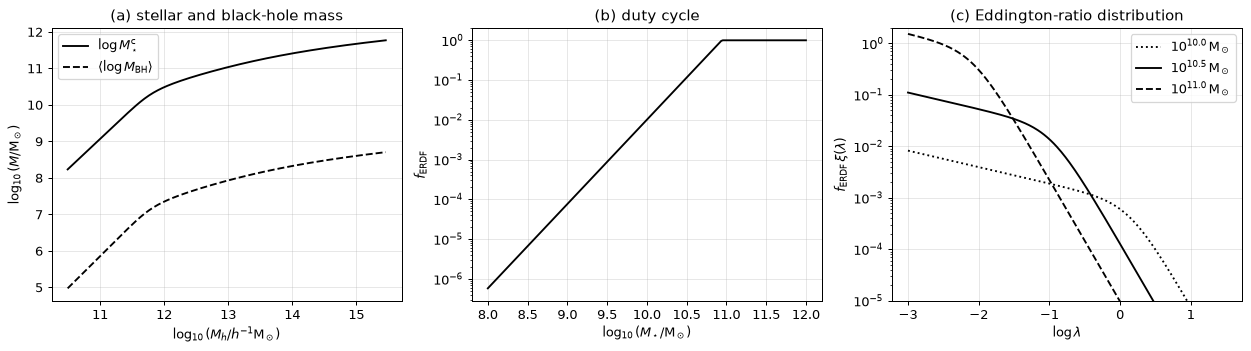

In [3]:
lg_ms_c = np.asarray(agn.log10_mstar(lgm, gp, h=h))
lg_mbh_c = np.asarray(agn.mean_log10_mbh(lgm, p, gp, h=h))
lg_ms = np.linspace(8.0, 12.0, 200)
loglam = np.linspace(-3.0, 1.5, 300)

fig, ax = plt.subplots(1, 3, figsize=(14.0, 4.0))
ax[0].plot(lgm[ok], lg_ms_c[ok], "k", label=r"$\log M_\star^{\rm c}$")
ax[0].plot(lgm[ok], lg_mbh_c[ok], "k--", label=r"$\langle\log M_{\rm BH}\rangle$")
ax[0].set(xlabel=r"$\log_{10}(M_h/h^{-1}{\rm M}_\odot)$", ylabel=r"$\log_{10}(M/{\rm M}_\odot)$",
          title="(a) stellar and black-hole mass")
ax[0].legend()
ax[1].semilogy(lg_ms, np.asarray(A.duty(lg_ms, p)), "k")
ax[1].set(xlabel=r"$\log_{10}(M_\star/{\rm M}_\odot)$", ylabel=r"$f_{\rm ERDF}$",
          title="(b) duty cycle")
for lg, ls in ((10.0, ":"), (10.5, "-"), (11.0, "--")):
    lstar = float(A.lstar_of_mstar(lg, p, Z))
    xi = np.asarray(A.erdf(loglam, lstar, p.delta1, p.delta2))
    xi = xi / np.trapezoid(xi, loglam)
    ax[2].semilogy(loglam, float(A.duty(lg, p)) * xi, "k" + ls, label=rf"$10^{{{lg}}}\,{{\rm M}}_\odot$")
ax[2].set(xlabel=r"$\log\lambda$", ylabel=r"$f_{\rm ERDF}\,\xi(\lambda)$", ylim=(1e-5, 2),
          title=r"(c) Eddington-ratio distribution")
ax[2].legend()
fig.tight_layout()

## The X-ray luminosity function

The intrinsic $2$–$10$ keV luminosity function the chain predicts at $z = 0.2$
(black), its central and satellite parts, and the published fits of Aird et al.
(2015) and Ueda et al. (2014) at the same redshift, converted to $h^{-1}$ units.
The soft-band ($0.5$–$2$ keV) function of the obscuration split is dashed.

log L_X = 42.0: Phi = 1.04e-03, aird15 6.98e-04
log L_X = 43.0: Phi = 4.04e-04, aird15 1.85e-04
log L_X = 44.0: Phi = 3.97e-05, aird15 4.60e-06
log L_X = 45.0: Phi = 2.55e-07, aird15 2.62e-08


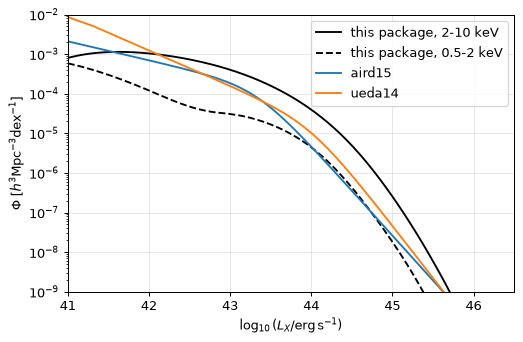

In [4]:
lx, phi = agn.xlf(field, p, gp)
lx, phi = np.asarray(lx), np.asarray(phi)
lx_s, phi_s = split.xlf(field, p, gp, band="soft", obsc=o)

fig, ax = plt.subplots()
ax.semilogy(lx, phi, "k", label="this package, 2-10 keV")
ax.semilogy(np.asarray(lx_s), np.asarray(phi_s), "k--", label="this package, 0.5-2 keV")
for name, c in (("aird15", "C0"), ("ueda14", "C1")):
    ax.semilogy(lx, np.asarray(A.xlf_in_h_units(name, lx, Z, h)), c, label=name)
ax.set(xlabel=r"$\log_{10}(L_X/{\rm erg\,s^{-1}})$",
       ylabel=r"$\Phi$ [$h^3{\rm Mpc}^{-3}{\rm dex}^{-1}$]", xlim=(41, 46.5), ylim=(1e-9, 1e-2))
ax.legend()
for l in (42.0, 43.0, 44.0, 45.0):
    print(f"log L_X = {l}: Phi = {np.interp(l, lx, phi):.2e}, "
          f"aird15 {float(A.xlf_in_h_units('aird15', np.array([l]), Z, h)[0]):.2e}")

## Occupation and the obscured fraction

*(a)* The occupation of haloes by AGNs above $L_X = 10^{42}$ erg/s in the hard
band, central galaxies at the halo centre and satellites on their profile.
*(b)* The obscured fraction against luminosity in haloes of $10^{12}$,
$10^{13}$ and $10^{14}\,h^{-1}{\rm M}_\odot$: the tilt $a_M$ moves the transition
with host mass, so obscured and unobscured AGNs differ in bias.

n_AGN = 9.132e-04 h^3 Mpc^-3, b_eff = 1.047
unobscured  b_eff = 1.245


obscured    b_eff = 1.037


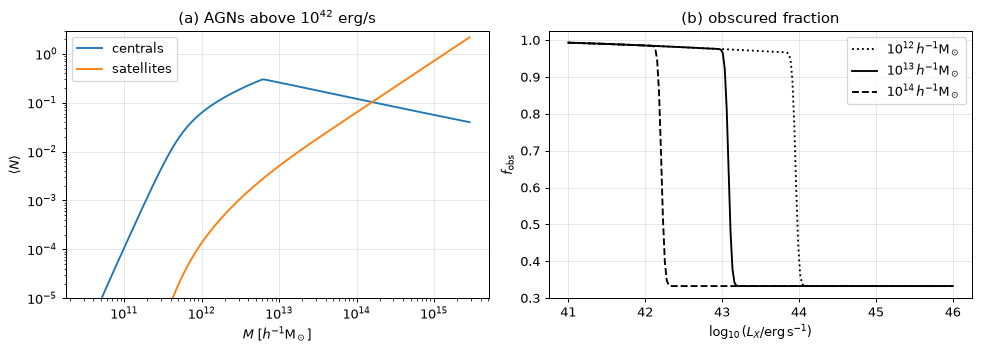

In [5]:
n_c, _ = agn.occupation(field, p, gp)
w = agn.weights(field, p, gp)
n_s = np.asarray(w.w_extended)[0] if w.w_extended is not None else 0 * m
lx_grid = np.linspace(41.0, 46.0, 200)

fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.0))
ax[0].loglog(m[ok], np.asarray(n_c)[ok], "C0", label="centrals")
ax[0].loglog(m[ok], n_s[ok], "C1", label="satellites")
ax[0].set(xlabel=r"$M\ [h^{-1}{\rm M}_\odot]$", ylabel=r"$\langle N\rangle$", ylim=(1e-5, 3),
          title=r"(a) AGNs above $10^{42}$ erg/s")
ax[0].legend()
for lg, ls in ((12.0, ":"), (13.0, "-"), (14.0, "--")):
    f = np.asarray(S.obscured_fraction(lx_grid, Z, o, log10m=lg)).ravel()
    ax[1].plot(lx_grid, f, "k" + ls, label=rf"$10^{{{lg:.0f}}}\,h^{{-1}}{{\rm M}}_\odot$")
ax[1].set(xlabel=r"$\log_{10}(L_X/{\rm erg\,s^{-1}})$", ylabel=r"$f_{\rm obs}$",
          title="(b) obscured fraction")
ax[1].legend()
fig.tight_layout()

print(f"n_AGN = {float(w.norm):.3e} h^3 Mpc^-3, b_eff = {float(agn.effective_bias(field, p, gp)):.3f}")
for branch in ("unobscured", "obscured"):
    print(f"{branch:11s} b_eff = {float(split.effective_bias(field, p, gp, branch=branch, obsc=o)):.3f}")

## Black holes

The black-hole mass function of every black hole above
$M_\star = 10^{8}\,{\rm M}_\odot$, active or not, central galaxies and
satellites together, and the density $\Omega_{\rm BH}$ they hold.

Omega_BH = 1.934e-06


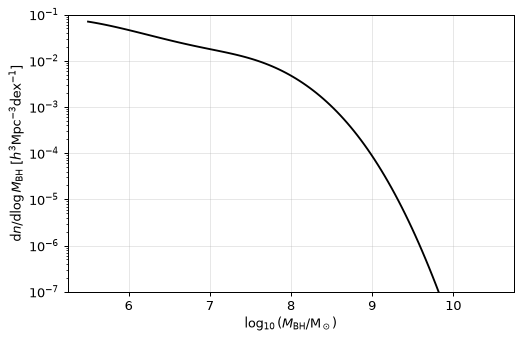

In [6]:
lg_mbh = np.linspace(5.5, 10.5, 120)
bhmf = np.asarray(agn.black_hole_mass_function(field, lg_mbh, p, gp))

fig, ax = plt.subplots()
ax.semilogy(lg_mbh, bhmf, "k")
ax.set(xlabel=r"$\log_{10}(M_{\rm BH}/{\rm M}_\odot)$",
       ylabel=r"${\rm d}n/{\rm d}\log M_{\rm BH}$ [$h^3{\rm Mpc}^{-3}{\rm dex}^{-1}$]",
       ylim=(1e-7, 1e-1))
print(f"Omega_BH = {float(agn.omega_bh(field, p, gp)):.3e}")

## Things to try

- Build the sector with `kbol="constant"` and compare its luminosity function
  with the default's.
- Switch to `selection="flux"` and print `agn.flux_limit_luminosity(field, p)`,
  the luminosity threshold the flux limit corresponds to at $z = 0.2$.
- Move `log10_ferdf_mslope` ($\beta_f$) and follow the faint end of the
  luminosity function and the bias of the AGNs.
- Set `f_duty_sat=0`: the AGN tracer loses its satellites and its one-halo term.

Previous: {doc}`layer3_galaxies`. Next: {doc}`layer3_hot_gas`.